# NC Margin Attack

## Setup

In [ ]:
import torch
import polars as pl

from shared import preprocess_metrics_df, SETUPS, setup
from privacy_and_grokking.artifacts.cache import get_artifact_path, get_training_config
from privacy_and_grokking.artifacts.local import mlflow_export_cache_path, get_plots_dir
from privacy_and_grokking.datasets import GpuDataset
from privacy_and_grokking.utils import get_device, Logger

## Data Collection

In [ ]:
v1 = mlflow_export_cache_path("canary-selection-v1")
df_v1 = preprocess_metrics_df(pl.read_parquet(v1))

In [3]:
df_v1.head()

run_id,run_name,step,timestamp,epoch,eval/generalization_gap,eval/nc/nc1,eval/nc/nc2_equinorm_weights,eval/nc/nc2_equiangularity,eval/nc/nc2_maximal_angle_equiangularity,eval/nc/nc4_test,eval/nc/nc2_equinorm,eval/nc/nc2_equiangularity_weights,eval/nc/nc2_maximal_angle_equiangularity_weights,eval/nc/nc4,eval/nc/nc3,eval/nc/rnc1/train_impl,eval/nc/rnc1/train,eval/nc/rnc1/train_mean_test_variance_impl,eval/nc/rnc1/test_impl,eval/nc/rnc1/train_mean_test_variance,eval/nc/rnc1/test,eval/train/canary_accuracy,eval/train/accuracy,eval/train/canary_loss/cross_entropy/mean,eval/train/canary_loss/cross_entropy/std,eval/train/canary_loss/mse/mean,eval/train/canary_loss/mse/std,eval/train/loss/cross_entropy/mean,eval/train/loss/cross_entropy/std,eval/train/loss/mse/std,eval/train/loss/mse/mean,eval/test/canary_accuracy,eval/test/accuracy,eval/test/canary_loss/mse/mean,eval/test/canary_loss/mse/std,eval/test/canary_loss/cross_entropy/mean,…,eval/weight_norm/mlp.2.bias,eval/weight_norm/attn.out_proj.bias,eval/weight_norm/token_embed.weight,eval/weight_norm/attn.in_proj_weight,eval/weight_norm/mlp.0.bias,eval/weight_norm/mlp.0.weight,eval/weight_norm/pos_embed,eval/weight_norm/mlp.2.weight,eval/grad_norm/vit.heads.head.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/grad_norm/vit.conv_proj.bias,eval/grad_norm/vit.encoder.pos_embedding,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/grad_norm/vit.heads.head.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/grad_norm/vit.class_token,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/grad_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/grad_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/grad_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.weight,eval/weight_norm/vit.class_token,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_bias,eval/weight_norm/vit.conv_proj.bias,eval/weight_norm/vit.heads.head.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.out_proj.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.weight,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.3.weight,eval/weight_norm/vit.conv_proj.weight,eval/weight_norm/vit.encoder.pos_embedding,eval/weight_norm/vit.encoder.layers.encoder_layer_0.mlp.0.bias,eval/weight_norm/vit.encoder.layers.encoder_layer_0.self_attention.in_proj_weight,eval/weight_norm/vit.heads.head.weight,title
str,str,i64,datetime[ms],f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,…,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,f64,str
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:47.098,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,…,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,null,"""(I) MLP (MSE) Grokking"""
"""003a54a7b3874e12b45472ef2bf706…","""SQUARE_WATERMARK_GROK_MNIST_MS…",0,2026-09-05 07:05:12.020,0.0,-0.000305,2.020342,0.038248,0.242497,0.185493,0.9234,0.214121,0.058478,0.110666,0.931579,1.995042,0.350759,0.141888,0.350787,0.345635,0.126295,0.124347,0.1,0.077895,68.045837,60.762383,3974.813477,5751.144531,66.919189,50.410038,2755.906738,1816.020142,0.07,0.0782,2343.800537,2474.350098,73.447357,…,null,null,null,null,null,null

In [4]:
runs = list(df_v1.filter((pl.col("run_name").str.contains("LABEL_NOISE")) & (pl.col("run_name").str.contains_any(list(SETUPS.keys())))).unique(subset=["run_id"])["run_id"])

In [5]:
runs = df_v1.filter((pl.col("run_name").str.contains("LABEL_NOISE_GROK_MNIST_MSE_MLP"))).unique(subset=["run_id"])[["run_id", "run_name"]]

In [6]:
run_id = runs["run_id"][0]
checkpoint_path = get_artifact_path(run_id=run_id, artifact_path="checkpoints/150000/model.pth")
config = get_training_config(run_id=run_id)

In [ ]:
Logger().setup()
keep_on_gpu = torch.cuda.is_available()
device = get_device()
data_container = config.data()
model = config.model(
    input_dim=data_container.input_shape,
    num_classes=data_container.num_classes,
)
model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
model.to(device)
model.train()

norm_mean = None
norm_std = None
if data_container.normalization is not None:
    norm_mean = torch.tensor(data_container.normalization.mean, device=device).view(-1, 1, 1)
    norm_std = torch.tensor(data_container.normalization.std, device=device).view(-1, 1, 1)

{"log_file": "/var/folders/_r/9n6ndj_d7k5b5yds9vn86n200000gn/T/2026-10-23T09-13-26_otsvyg07.log", "event": "Logger initialized", "timestamp": "2026-10-23T07:13:26.761632Z", "level": "info"}


In [8]:
model

MLP(
  (fc1): Linear(in_features=784, out_features=200, bias=True)
  (fc2): Linear(in_features=200, out_features=200, bias=True)
  (fc3): Linear(in_features=200, out_features=10, bias=True)
)

In [ ]:
def maybe_gpu_dataset(dataset):
        if keep_on_gpu:
            return GpuDataset(dataset, device)
        return dataset

def safe_collate(batch):
    if isinstance(batch[0], tuple) and len(batch[0]) == 2:
        xs, ys = zip(*batch)
        if any(isinstance(y, torch.Tensor) for y in ys) and any(not isinstance(y, torch.Tensor) for y in ys):
            ys = [y if isinstance(y, torch.Tensor) else torch.tensor(y) for y in ys]
            batch = list(zip(xs, ys))
    return torch.utils.data.default_collate(batch)

def get_dl_kwargs(dataset):
    is_gpu = isinstance(dataset, GpuDataset)
    return {
        "batch_size": 200,
        "num_workers": 0 if is_gpu else config.num_workers,
        "pin_memory": (config.num_workers > 0 and keep_on_gpu and not is_gpu),
        "persistent_workers": (config.num_workers > 0 and not is_gpu),
        "collate_fn": safe_collate,
    }

train_ds = maybe_gpu_dataset(data_container.train)
train_loader = torch.utils.data.DataLoader(train_ds, **get_dl_kwargs(train_ds))

train_canary_ds = maybe_gpu_dataset(data_container.train_canary)
train_canary_loader = torch.utils.data.DataLoader(train_canary_ds, **get_dl_kwargs(train_canary_ds))

test_ds = maybe_gpu_dataset(data_container.test)
test_loader = torch.utils.data.DataLoader(test_ds, **get_dl_kwargs(test_ds))

test_canary_ds = maybe_gpu_dataset(data_container.test_canary)
test_canary_loader = torch.utils.data.DataLoader(test_canary_ds, **get_dl_kwargs(test_canary_ds))

classifier_weights = list(model.classifier().parameters())[0]
w_dist = torch.cdist(classifier_weights, classifier_weights).clamp(min=1e-12) # On diagonal always 0
iu, ju = torch.triu_indices(classifier_weights.shape[0], classifier_weights.shape[0], offset=1)

In [31]:
dfs = []
for type, loader in [("train", train_loader), ("train_canary", train_canary_loader), ("test", test_loader), ("test_canary", test_canary_loader)]:
    actual_list = []
    pred_list = []
    class_wise_distance_list = []
    distance_list = []

    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            if norm_mean is not None and norm_std is not None:
                x = (x - norm_mean) / norm_std
            y_pred, z = model(x, verbose=True)
            d_all = torch.cdist(z, classifier_weights)
            
            actual_list.append(y)
            pred_list.append(y_pred.argmax(dim=-1))
            distance_list.append(d_all)
            class_wise_distance_list.append((y_pred[:, iu] - y_pred[:, ju]) / w_dist[iu, ju])

        class_wise_distances = torch.cat(class_wise_distance_list).T.numpy()
        distances = torch.cat(distance_list).T.numpy()
        df_new = pl.DataFrame({"type": type, "pred": torch.cat(pred_list).numpy(), "actual": torch.cat(actual_list).numpy(), **{f"d{i}": distances[i] for i in range(distances.shape[0])}, **{f"cd-{iu[i]}-{ju[i]}": class_wise_distances[i] for i in range(class_wise_distances.shape[0])}})
        dfs.append(df_new)
df = pl.concat(dfs)

In [81]:
w_dist

tensor([[1.0000e-12, 3.9451e-01, 3.9331e-01, 3.8788e-01, 3.8380e-01, 4.0237e-01,
         3.7680e-01, 3.8091e-01, 4.0775e-01, 4.2798e-01],
        [3.9451e-01, 1.0000e-12, 4.1552e-01, 3.9968e-01, 3.9590e-01, 4.1429e-01,
         3.8923e-01, 3.9303e-01, 4.1904e-01, 4.3948e-01],
        [3.9331e-01, 4.1552e-01, 1.0000e-12, 3.9732e-01, 3.9452e-01, 4.1214e-01,
         3.9700e-01, 3.9047e-01, 4.1702e-01, 4.3927e-01],
        [3.8788e-01, 3.9968e-01, 3.9732e-01, 1.0000e-12, 3.8917e-01, 4.0719e-01,
         3.8247e-01, 3.8506e-01, 4.1210e-01, 4.3394e-01],
        [3.8380e-01, 3.9590e-01, 3.9452e-01, 3.8917e-01, 1.0000e-12, 4.0352e-01,
         3.7841e-01, 3.8205e-01, 4.0886e-01, 4.4222e-01],
        [4.0237e-01, 4.1429e-01, 4.1214e-01, 4.0719e-01, 4.0352e-01, 1.0000e-12,
         3.9682e-01, 4.0058e-01, 4.2723e-01, 4.4741e-01],
        [3.7680e-01, 3.8923e-01, 3.9700e-01, 3.8247e-01, 3.7841e-01, 3.9682e-01,
         1.0000e-12, 3.7532e-01, 4.0237e-01, 4.2293e-01],
        [3.8091e-01, 3.9303

In [32]:
df

type,pred,actual,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,cd-0-1,cd-0-2,cd-0-3,cd-0-4,cd-0-5,cd-0-6,cd-0-7,cd-0-8,cd-0-9,cd-1-2,cd-1-3,cd-1-4,cd-1-5,cd-1-6,cd-1-7,cd-1-8,cd-1-9,cd-2-3,cd-2-4,cd-2-5,cd-2-6,cd-2-7,cd-2-8,cd-2-9,cd-3-4,cd-3-5,cd-3-6,cd-3-7,cd-3-8,cd-3-9,cd-4-5,cd-4-6,cd-4-7,cd-4-8,cd-4-9,cd-5-6,cd-5-7,cd-5-8,cd-5-9,cd-6-7,cd-6-8,cd-6-9,cd-7-8,cd-7-9,cd-8-9
str,i64,i64,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""train""",0,0,3.446294,3.727609,3.730567,3.728015,3.725702,3.731337,3.723848,3.729185,3.732474,3.731327,2.533112,2.540584,2.576032,2.603797,2.483405,2.651987,2.623333,2.450741,2.334838,-0.000201,-0.000346,0.000018,-0.000197,-0.000172,-0.00021,-0.000077,-0.000142,-0.000138,0.000229,0.000004,0.000041,0.000003,0.000123,0.000047,0.000373,0.000139,0.000186,0.000145,0.000257,0.000174,-0.00022,-0.000196,-0.000234,-0.000096,-0.000158,0.000037,-0.000002,0.000116,0.000043,-0.000041,0.000087,0.00001,0.000124,0.000046,-0.000067
"""train""",0,0,3.443458,3.724778,3.727735,3.725184,3.72287,3.728506,3.721016,3.726355,3.729644,3.728498,2.531136,2.538583,2.574024,2.601777,2.48145,2.649942,2.621286,2.448807,2.333014,-0.000219,-0.000344,0.000029,-0.000215,-0.00015,-0.00021,-0.000099,-0.000145,-0.000117,0.000259,0.000005,0.000082,0.000022,0.000119,0.000062,0.000383,0.00012,0.000207,0.000143,0.000234,0.00017,-0.000248,-0.000184,-0.000245,-0.000129,-0.00017,0.000077,0.000016,0.000111,0.000056,-0.000064,0.000042,-0.000013,0.000101,0.000044,-0.00005
"""train""",0,0,3.448133,3.729442,3.732399,3.729849,3.727535,3.73317,3.725682,3.73102,3.734307,3.733158,2.534366,2.541858,2.57732,2.605084,2.484653,2.653294,2.624659,2.451974,2.335997,-0.000185,-0.000334,0.000015,-0.00018,-0.000179,-0.000183,-0.000058,-0.000141,-0.000142,0.000211,0.000006,0.000018,0.000013,0.000127,0.000035,0.000359,0.000145,0.000167,0.00016,0.000266,0.000166,-0.0002,-0.000201,-0.000204,-0.000074,-0.000153,0.000012,0.000007,0.000118,0.000029,-0.000006,0.000114,0.000019,0.000118,0.000024,-0.000083
"""train""",0,0,3.444277,3.725597,3.728554,3.726003,3.723689,3.729325,3.721835,3.727173,3.730463,3.729317,2.531716,2.53917,2.574609,2.602369,2.482022,2.65054,2.62188,2.449374,2.33355,-0.000214,-0.000349,0.000024,-0.000211,-0.000159,-0.000217,-0.000093,-0.000144,-0.000127,0.00025,0.000003,0.000069,0.00001,0.00012,0.000058,0.000383,0.000128,0.000204,0.000141,0.000244,0.000176,-0.000241,-0.000188,-0.000248,-0.000118,-0.000165,0.000065,0.000006,0.000114,0.000054,-0.000062,0.000057,-0.000004,0.000114,0.000051,-0.000054
"""train""",0,0,3.44826,3.72957,3.732527,3.729976,3.727663,3.733297,3.725809,3.731147,3.734434,3.733286,2.534462,2.541955,2.577415,2.605182,2.484747,2.653392,2.624753,2.452068,2.336087,-0.000185,-0.000338,0.000014,-0.00018,-0.000182,-0.000188,-0.000057,-0.000139,-0.000146,0.000209,0.000005,0.000015,0.000008,0.000127,0.000036,0.000361,0.000148,0.000168,0.000158,0.000269,0.00017,-0.000199,-0.000202,-0.000208,-0.000072,-0.000151,0.00001,0.000002,0.000119,0.00003,-0.000008,0.000117,0.000023,0.000123,0.00003,-0.000083
…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…,…
"""test_canary""",9,5,4.091664,4.094113,4.096963,4.094549,4.092348,4.09766,4.090587,4.095701,4.098719,3.832855,0.000729,0.002162,0.001084,0.000462,0.002069,-0.000514,0.002189,0.002397,-2.451348,0.001354,0.000332,-0.000279,0.001315,-0.001237,0.001389,0.001645,-2.387846,-0.001082,-0.001706,-0.000043,-0.00263,-0.000043,0.000305,-2.390278,-0.000625,0.001012,-0.001606,0.001073,0.001351,-2.41866,0.001624,-0.00098,0.001718,0.001957,-2.372838,-0.002587,0.000003,0.000339,-2.34675,0.002738,0.00291,-2.48017,0.000354,-2.453702,-2.321216
"""test_canary""",1,7,2.769679,2.562479,2.781001,2.77491,2.775441,2.713808,2.767804,2.711889,2.782532,2.622766,-1.424927,0.026893,0.008036,0.034806,-0.439647,

In [29]:
df["type"].value_counts(sort=True)

type,count
str,u32
"""test""",10000
"""train""",950
"""test_canary""",100
"""train_canary""",50


In [25]:
df.estimated_size("gb")*15*500

18.297918140888214

## Analysis

In [36]:
setup()
PLOTS = get_plots_dir()

In [37]:
import matplotlib.pyplot as plt

In [44]:
df_type_col

type,pred,actual,d0,d1,d2,d3,d4,d5,d6,d7,d8,d9,cd-0-1,cd-0-2,cd-0-3,cd-0-4,cd-0-5,cd-0-6,cd-0-7,cd-0-8,cd-0-9,cd-1-2,cd-1-3,cd-1-4,cd-1-5,cd-1-6,cd-1-7,cd-1-8,cd-1-9,cd-2-3,cd-2-4,cd-2-5,cd-2-6,cd-2-7,cd-2-8,cd-2-9,cd-3-4,cd-3-5,cd-3-6,cd-3-7,cd-3-8,cd-3-9,cd-4-5,cd-4-6,cd-4-7,cd-4-8,cd-4-9,cd-5-6,cd-5-7,cd-5-8,cd-5-9,cd-6-7,cd-6-8,cd-6-9,cd-7-8,cd-7-9,cd-8-9
str,i64,i64,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32,f32
"""test_canary""",9,6,3.508462,3.511373,3.514761,3.511897,3.509713,3.515579,3.507178,3.513305,3.473903,3.240986,0.001217,0.00324,0.001728,0.004616,0.003175,-0.000779,0.003439,-0.364345,-2.16439,0.001911,0.000475,0.003262,0.001925,-0.001988,0.002111,-0.355674,-2.108837,-0.00152,0.001261,0.000009,-0.003948,0.000091,-0.359301,-2.111661,0.00283,0.001492,-0.00252,0.001661,-0.36213,-2.136218,-0.001224,-0.005457,-0.001209,-0.367692,-2.098723,-0.003959,0.00008,-0.350727,-2.07325,0.004272,-0.368493,-2.189549,-0.369524,-2.167809,-1.719193
"""test_canary""",9,4,3.86418,3.867664,3.872221,3.868674,3.800083,3.868906,3.862646,3.742036,3.874736,3.643907,0.00946,0.026086,0.015439,-0.646817,-0.013539,-0.004548,-1.260727,0.031719,-1.987418,0.01571,0.005645,-0.636478,-0.022157,-0.013991,-1.231343,0.021958,-1.943895,-0.010751,-0.65525,-0.038112,-0.03016,-1.256142,0.006411,-1.959693,-0.653272,-0.028085,-0.020137,-1.262692,0.016853,-1.973931,0.601713,0.651503,-0.607183,0.638805,-1.362069,0.00941,-1.185206,0.043024,-1.888931,-1.274947,0.036402,-2.007105,1.215912,-0.865501,-1.908751
"""test_canary""",9,1,3.825451,3.828159,3.831256,3.828624,3.806902,3.832031,3.82428,3.829961,3.833277,3.558215,0.001597,0.003505,0.001953,-0.191251,0.003666,-0.000707,0.004129,0.00505,-2.360503,0.001801,0.000319,-0.186999,0.00204,-0.002303,0.002399,0.00341,-2.300158,-0.001563,-0.189549,0.000234,-0.004143,0.000498,0.001632,-2.30297,-0.190556,0.001763,-0.002676,0.002118,0.003159,-2.329839,0.185562,0.193272,0.196245,0.184565,-2.11853,-0.004388,0.000244,0.001367,-2.261286,0.0049,0.005779,-2.388069,0.001199,-2.364569,-2.237664
"""test_canary""",9,8,3.747089,3.749661,3.752447,3.749993,3.748746,3.753218,3.745983,3.751121,3.754389,3.487761,-0.000236,-0.00192,-0.001286,0.009357,-0.001821,0.00018,-0.001512,-0.001306,-2.247204,-0.001593,-0.001016,0.009306,-0.001544,0.000414,-0.001228,-0.001049,-2.188178,0.000645,0.011017,0.000055,0.002073,0.000459,0.000534,-2.187726,0.01051,-0.000574,0.001482,-0.0002,-0.000081,-2.2152,-0.010715,-0.009311,-0.010907,-0.010086,-2.182986,0.002017,0.000391,0.000468,-2.147974,-0.001715,-0.001492,-2.274207,0.000107,-2.24623,-2.124752
"""test_canary""",9,3,3.964306,3.966792,3.969658,3.967219,3.964872,3.970377,3.963216,3.968358,3.971437,3.70407,0.000314,0.000984,0.000422,-0.000983,0.00091,-0.000285,0.000991,0.000941,-2.386686,0.000633,0.000099,-0.001266,0.000584,-0.000594,0.000645,0.00062,-2.324504,-0.000562,-0.001937,-0.000051,-0.001245,-0.000024,-0.000008,-2.326223,-0.001389,0.000497,-0.000708,0.000556,0.000534,-2.354294,0.001842,0.000713,0.001975,0.001861,-2.309005,-0.001193,0.000028,0.000041,-2.283854,0.001291,0.00122,-2.414941,0.000015,-2.387963,-2.258731
"""test_canary""",9,5,4.091664,4.094113,4.096963,4.094549,4.092348,4.09766,4.090587,4.095701,4.098719,3.832855,0.000729,0.002162,0.001084,0.000462,0.002069,-0.000514,0.002189,0.002397,-2.451348,0.001354,0.000332,-0.000279,0.001315,-0.001237,0.001389,0.001645,-2.387846,-0.001082,-0.001706,-0.000043,-0.00263,-0.000043,0.000305,-2.390278,-0.000625,0.001012,-0.001606,0.001073,0.001351,-2.41866,0.001624,-0.00098,0.001718,0.001957,-2.372838,-0.002587,0.000003,0.000339,-2.34675,0.002738,0.00291,-2.48017,0.000354,-2.453702,-2.321216
"""test_canary""",9,0,4.213735,4.216114,4.218873,4.21653,4.214475,4.21955,4.212688,4.217649,4.220583,3.96327,0.000736,0.00208,0.001023,0.001296,0.001993,-0.000523,0.00212,0.002375,-2.447974,0.00127,0

In [50]:
df_type["pred"].value_counts()

pred,count
i64,u32
9,95
6,95
7,95
1,95
0,95
8,95
3,95
4,95
2,95


In [65]:
df.filter((pl.col("type") == "train") & (pl.col("pred") == ))["cd-0-2"]

cd-0-2
f32
2.540584
2.538583
2.541858
2.53917
2.541955
…
2.540196
2.540278
2.540295


In [78]:
import numpy as np

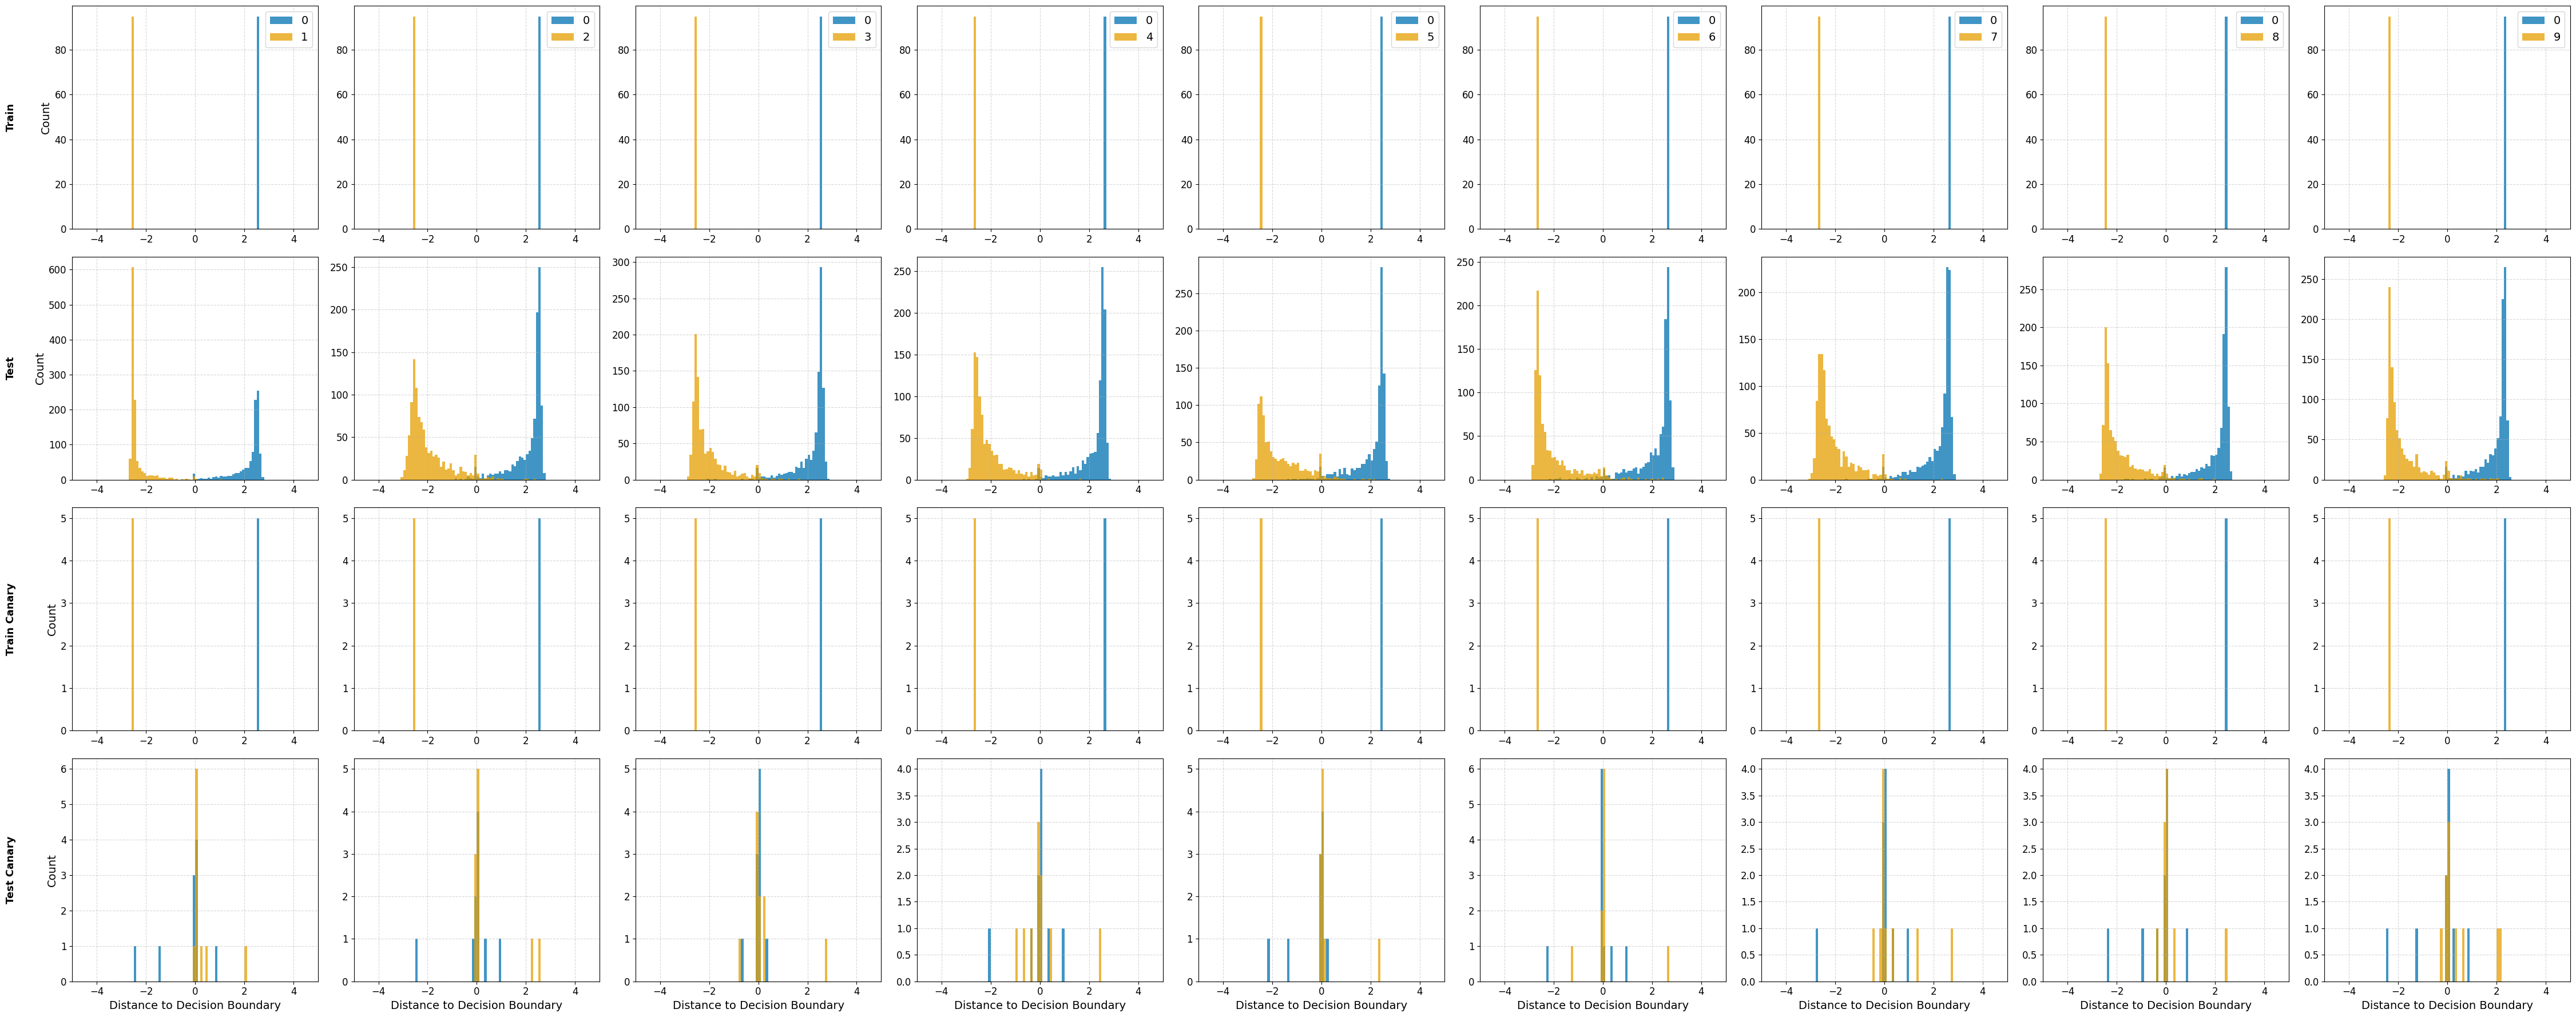

In [103]:
ROWS = ["train", "test", "train_canary", "test_canary"]
N_COLS = 9
N_ROWS = len(ROWS)

fig, axes = plt.subplots(N_ROWS, N_COLS, figsize=(5 * N_COLS, 4.5 * N_ROWS))

for row in range(N_ROWS):
    type = ROWS[row]
    df_type = df.filter((pl.col("type") == type))
    df_type_0 = df_type.filter((pl.col("actual") == 0))

    for col in range(1, N_COLS+1):
        ax = axes[row, col-1]
        df_type_col = df_type.filter((pl.col("actual") == col))
        bins = np.linspace(-5, 5, 101)
        ax.hist(df_type_0[f"cd-0-{col}"], bins=bins, label="0", alpha=0.75)
        ax.hist(df_type_col[f"cd-0-{col}"], bins=bins, label=col, alpha=0.75)
        # print(type, col, len(df_type_0), len(df_type_col), df_type_0[f"cd-0-{col}"].mean(), df_type_col[f"cd-0-{col}"].mean())
        ax.set_xlim(-5, 5)
        if row == 0:
            ax.legend()

    axes[row, 0].annotate(
        " ".join([s.capitalize() for s in type.split("_")]),
        xy=(-0.25, 0.5),
        xycoords="axes fraction",
        fontsize=13,
        fontweight="bold",
        ha="center",
        va="center",
        rotation=90,
    )
    axes[row, 0].set_ylabel("Count")

    # Y-Labels
    if row == N_ROWS - 1:
        for i in range(N_COLS):
            axes[row, i].set_xlabel("Distance to Decision Boundary")

    # for col, (canary, column_name) in enumerate(CANARIES.items()):
    #     df = (
    #         metrics_df
    #         .filter((pl.col("title") == title) & (pl.col("run_name").str.contains(canary)))
    #         .group_by(["title", "step"])
    #         .agg([
    #             cs.numeric().exclude("step").mean().name.suffix("_mean"),
    #             cs.numeric().exclude("step").std().name.suffix("_std"),
    #         ])
    #         .sort(["title", "step"])
    #     )
        
    #     if (len(df) <= 0):
    #         ax[col].text(0.5, 0.5, "N/A", horizontalalignment="center", verticalalignment="center")
    #         continue

    #     if row == 0:
    #         ax[col].set_title(column_name, fontsize=13, fontweight="bold")
    #     plot_region(ax[col], df, "eval/train/accuracy", "Train")
    #     plot_region(ax[col], df, "eval/test/accuracy", "Test")
    #     plot_region(ax[col], df, "eval/train/canary_accuracy", "Canary Train")
    #     plot_region(ax[col], df, "eval/test/canary_accuracy", "Canary Test")
    #     ax[col].set_ylabel("Accuracy")
    #     ax[col].set_ylim(-0.05, 1.05)
    #     ax[col].set_xlim(-0.05 * df["step"].max(), df["step"].max() * 1.05)
    #     ax[col].xaxis.set_major_locator(MultipleLocator(25_000 if df["step"].max() > 50_000 else 10_000))
    #     ax[col].xaxis.set_major_formatter(EngFormatter(unit="", places=0, sep=""))
    #     ax[col].legend()

plt.tight_layout()
# fig.savefig(PLOTS / f"canary_selection_v1_{str(date.today())}.pdf", format="pdf", bbox_inches="tight")

## Attack #1: We know the exact values.

In [116]:
bins = np.linspace(-5, 5, 1001)
df.filter((pl.col("type") == "train") & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))["cd-0-1"].abs().hist(bins=bins).sort("count")

breakpoint,category,count
f64,cat,u32
-4.99,"""[-5.0, -4.99]""",0
-4.98,"""(-4.99, -4.98]""",0
-4.97,"""(-4.98, -4.97]""",0
-4.96,"""(-4.97, -4.96]""",0
-4.95,"""(-4.96, -4.95]""",0
…,…,…
4.98,"""(4.97, 4.98]""",0
4.99,"""(4.98, 4.99]""",0
5.0,"""(4.99, 5.0]""",0


In [117]:
df.filter((pl.col("type") == "test") & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))["cd-0-1"].abs().hist(bins=bins).sort("count")

breakpoint,category,count
f64,cat,u32
-4.99,"""[-5.0, -4.99]""",0
-4.98,"""(-4.99, -4.98]""",0
-4.97,"""(-4.98, -4.97]""",0
-4.96,"""(-4.97, -4.96]""",0
-4.95,"""(-4.96, -4.95]""",0
…,…,…
2.51,"""(2.5, 2.51]""",94
2.53,"""(2.52, 2.53]""",95
2.56,"""(2.55, 2.56]""",119


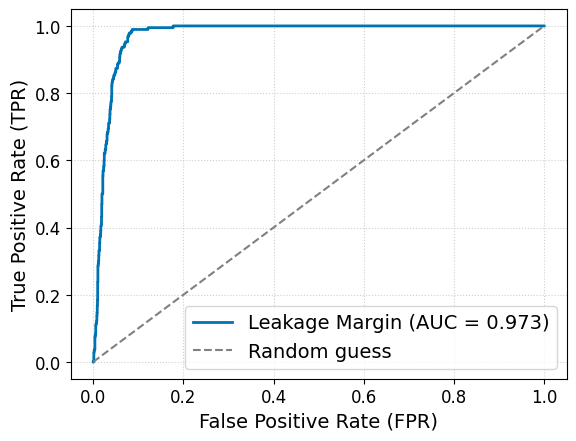

In [149]:
# Reference per Class for only one Class
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

reference = df.filter((pl.col("type") == "train") & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))["cd-0-1"].abs().median()
df_attack = df.filter(((pl.col("type") == "train") | (pl.col("type") == "test")) & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))
scores = -(df_attack["cd-0-1"].abs() - reference).abs()

auc_val = roc_auc_score(df_attack["type"] == "train", scores)
fpr, tpr, thresholds = roc_curve(df_attack["type"] == "train", scores, drop_intermediate=False)

plt.plot(fpr, tpr, lw=2, label=f"Leakage Margin (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
# Reference per Class for all Classes but distance 
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

reference = df.filter((pl.col("type") == "train") & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))["cd-0-1"].abs().median()
df_attack = df.filter(((pl.col("type") == "train") | (pl.col("type") == "test")) & ((pl.col("actual") == 0) | (pl.col("actual") == 1)))
scores = -(df_attack["cd-0-1"].abs() - reference).abs()

auc_val = roc_auc_score(df_attack["type"] == "train", scores)
fpr, tpr, thresholds = roc_curve(df_attack["type"] == "train", scores, drop_intermediate=False)

plt.plot(fpr, tpr, lw=2, label=f"Leakage Margin (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

In [ ]:
# TODO: Pro Klasse AUC und ROC displayen

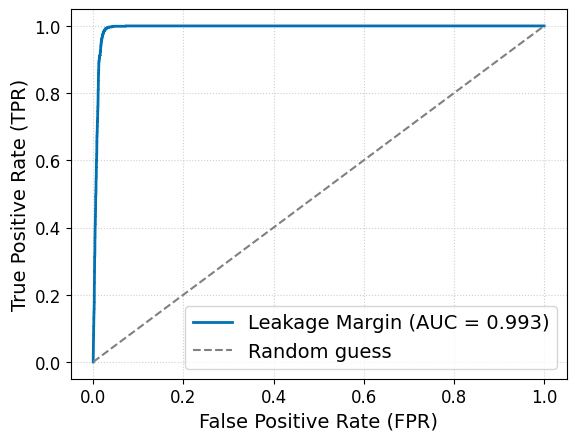

In [ ]:
# Reference per Class for only all Classes
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

expr = pl.when(pl.col("actual") <= 1).then(pl.col("cd-0-1"))
for i in range(2, 10):
    expr = expr.when(pl.col("actual") == i).then(pl.col(f"cd-0-{i}"))
expr = expr.otherwise(None)
df_expanded = df.with_columns(selected_value=expr)
references = df_expanded.filter((pl.col("type") == "train"))[["actual", "selected_value"]].group_by("actual").agg(pl.col("selected_value").abs().median().alias("reference"))
df_attack = df_expanded.filter(((pl.col("type") == "train") | (pl.col("type") == "test"))).join(references, on="actual")
scores = -(df_attack["selected_value"].abs() - df_attack["reference"]).abs()

auc_val = roc_auc_score(df_attack["type"] == "train", scores)
fpr, tpr, thresholds = roc_curve(df_attack["type"] == "train", scores, drop_intermediate=False)

plt.plot(fpr, tpr, lw=2, label=f"Leakage Margin (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

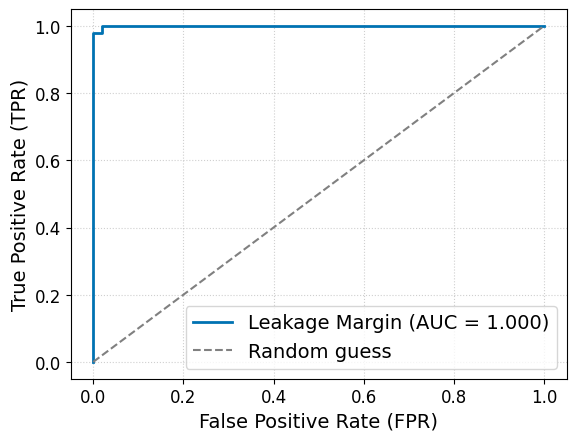

In [176]:
# Reference per Class for only all Classes
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

expr = pl.when(pl.col("actual") <= 1).then(pl.col("cd-0-1"))
for i in range(2, 10):
    expr = expr.when(pl.col("actual") == i).then(pl.col(f"cd-0-{i}"))
expr = expr.otherwise(None)
df_expanded = df.with_columns(selected_value=expr)
references = df_expanded.filter((pl.col("type") == "train_canary"))[["actual", "selected_value"]].group_by("actual").agg(pl.col("selected_value").abs().median().alias("reference"))
df_attack = df_expanded.filter(((pl.col("type") == "train_canary") | (pl.col("type") == "test_canary"))).join(references, on="actual")
scores = -(df_attack["selected_value"].abs() - df_attack["reference"]).abs()

auc_val = roc_auc_score(df_attack["type"] == "train_canary", scores)
fpr, tpr, thresholds = roc_curve(df_attack["type"] == "train_canary", scores, drop_intermediate=False)

plt.plot(fpr, tpr, lw=2, label=f"Leakage Margin (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

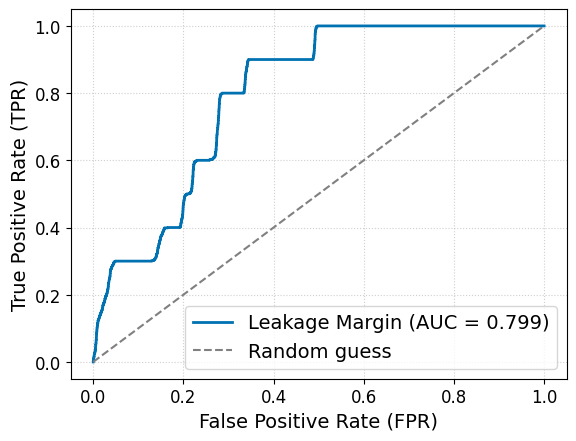

In [157]:
# Reference Across all Classes
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

expr = pl.when(pl.col("actual") <= 1).then(pl.col("cd-0-1"))
for i in range(2, 10):
    expr = expr.when(pl.col("actual") == i).then(pl.col(f"cd-0-{i}"))
expr = expr.otherwise(None)
df_expanded = df.with_columns(selected_value=expr)

reference = df_expanded.filter((pl.col("type") == "train"))["selected_value"].abs().median()
df_attack = df_expanded.filter(((pl.col("type") == "train") | (pl.col("type") == "test")))
scores = -(df_attack["selected_value"].abs() - reference).abs()

auc_val = roc_auc_score(df_attack["type"] == "train", scores)
fpr, tpr, thresholds = roc_curve(df_attack["type"] == "train", scores, drop_intermediate=False)

plt.plot(fpr, tpr, lw=2, label=f"Leakage Margin (AUC = {auc_val:.3f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Random guess")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc="lower right")
plt.grid(True, linestyle=":", alpha=0.6)
plt.show()

## Attack #2: We estimate the exact values using a shadow model.